# 02 - Visualization

Goal: explore the six financial ratios visually before building the dashboard.

Input: `data/processed/ratios.csv` (created by `src/compute_ratios.py`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

ratios = pd.read_csv("../data/processed/ratios.csv")
ratios.head()

,COMPANY,CD_CVM,YEAR,current_ratio,gross_margin,operating_margin,net_margin,roe,debt_ratio
0,Lojas Renner,8133,2021,1.758185,0.583867,0.076994,0.059888,0.064560,0.542003
1,Lojas Renner,8133,2022,1.863339,0.601668,0.106050,0.097332,0.128050,0.523024
2,Lojas Renner,8133,2023,1.627168,0.602337,0.065144,0.071532,0.097167,0.509668
3,Lojas Renner,8133,2024,1.610535,0.605551,0.087234,0.082893,0.111081,0.470996
4,Lojas Renner,8133,2025,1.694220,0.617070,0.113533,0.092079,0.139396,0.467224


## Chart settings

Two rules guide the choices below:

- **Color follows the company**, never its position: each company keeps the same
  color in every chart, so the reader learns it once.
- **Thin, quiet chart elements**: light grid, no top/right borders,
  so the data stands out.

In [2]:
COMPANY_COLORS = {
    "Magazine Luiza": "#2a78d6",  # blue
    "Lojas Renner": "#eb6834",    # orange
    "Grupo SBF": "#1baf7a",       # aqua
    "C&A": "#eda100",             # yellow
}

RATIO_LABELS = {
    "current_ratio": "Current ratio",
    "gross_margin": "Gross margin",
    "operating_margin": "Operating margin",
    "net_margin": "Net margin",
    "roe": "ROE",
    "debt_ratio": "Debt ratio",
}

# current_ratio is a multiple (e.g. 1.6x); every other ratio is a percentage
PERCENT_RATIOS = ["gross_margin", "operating_margin", "net_margin", "roe", "debt_ratio"]

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titleweight": "bold",
})

## One ratio, all companies

A **line chart** fits here: the question is "how did each company change over time?".
Each line ends with the company name (a *direct label*), so the reader does not need
to look back and forth at a legend.

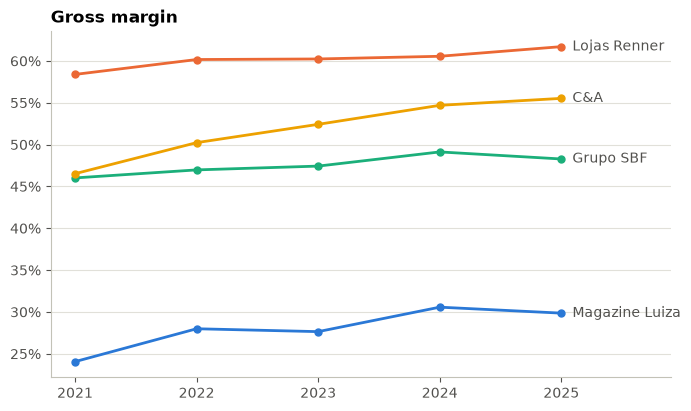

In [3]:
def plot_ratio(ratio, ax=None):
    """Draw one ratio over time, one line per company."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4.5))

    for company, color in COMPANY_COLORS.items():
        data = ratios[ratios["COMPANY"] == company]
        ax.plot(data["YEAR"], data[ratio], color=color, linewidth=2, marker="o", markersize=5, label=company)

    if ratio in PERCENT_RATIOS:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    if ratios[ratio].min() < 0:
        ax.axhline(0, color="#898781", linewidth=1)  # zero line when there are losses

    ax.set_title(RATIO_LABELS[ratio], loc="left")
    ax.set_xticks(sorted(ratios["YEAR"].unique()))
    return ax


ax = plot_ratio("gross_margin")

# Direct labels at the end of each line
last_year = ratios["YEAR"].max()
for company, color in COMPANY_COLORS.items():
    value = ratios[(ratios["COMPANY"] == company) & (ratios["YEAR"] == last_year)]["gross_margin"].iloc[0]
    ax.annotate(company, xy=(last_year, value), xytext=(8, 0), textcoords="offset points",
                va="center", color="#52514e")

ax.set_xlim(right=last_year + 0.9)  # room for the labels
plt.show()

## All six ratios side by side (small multiples)

Putting the six charts in a grid gives an overview of each company's profile at once.
Each chart keeps **its own y-axis**: margins, ROE and the current ratio have very
different scales.

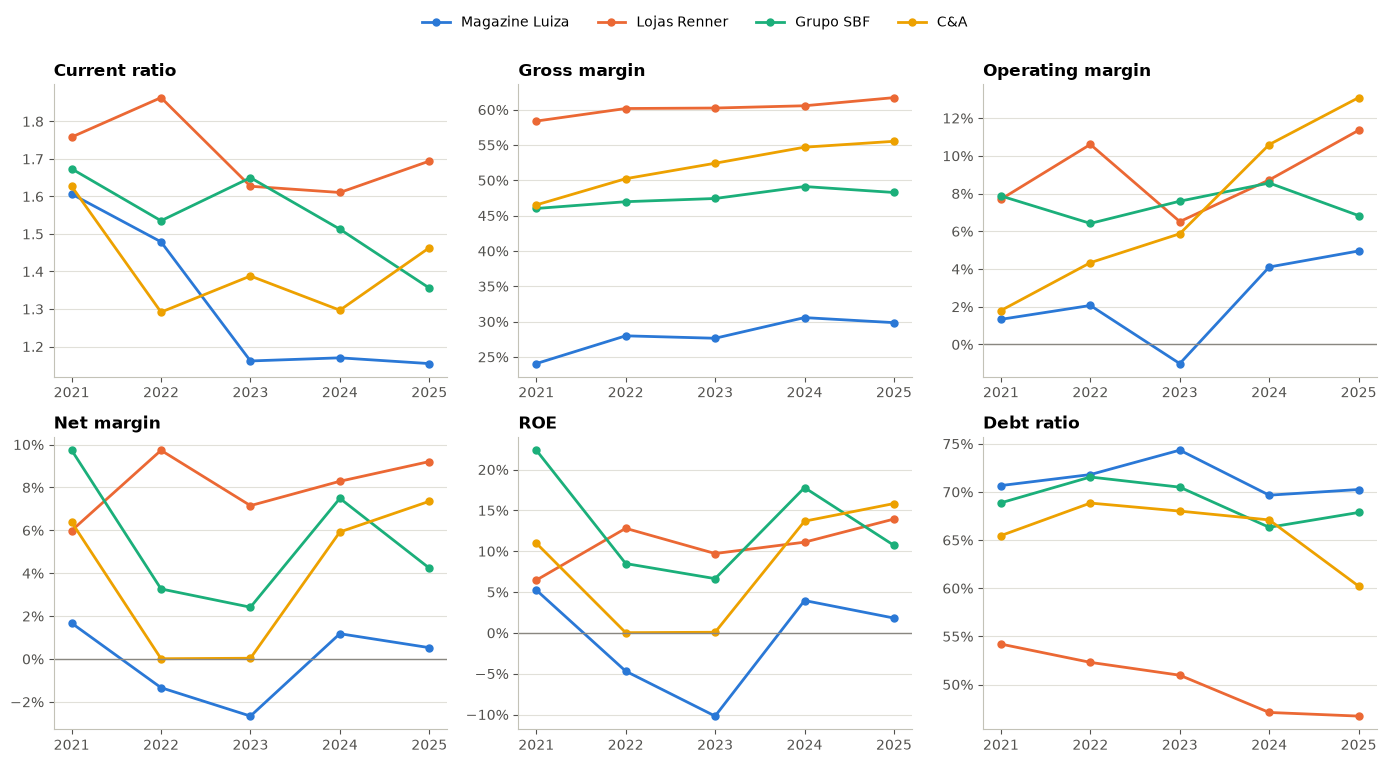

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))

for ax, ratio in zip(axes.flatten(), RATIO_LABELS.keys()):
    plot_ratio(ratio, ax=ax)

# A single legend for the whole figure
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))

fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## A number that needs a warning: C&A in 2021

C&A's 2021 net margin (6.4%) and ROE (11.0%) look healthy, but they come almost entirely
from a **one-off tax gain**: a R$ 311 million deferred tax asset recognized after the
Supreme Court (STF) ruling on IRPJ/CSLL over Selic interest (DFP 2021, note 14).
According to the management report, without it C&A would have reported a net loss.

A chart should not hide this, so we add an annotation on the point.

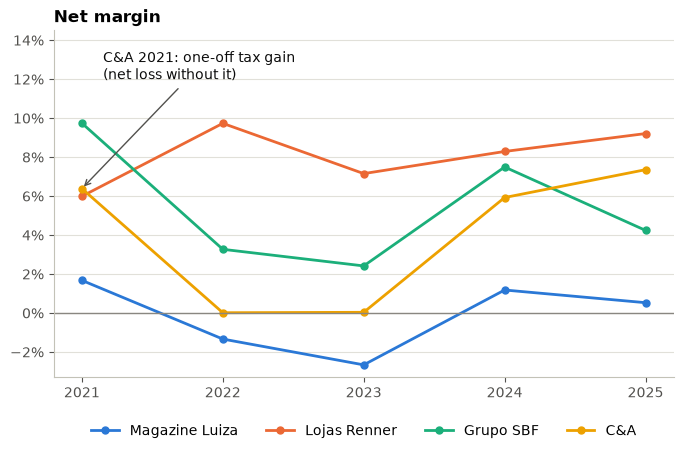

In [5]:
ax = plot_ratio("net_margin")

cea_2021 = ratios[(ratios["COMPANY"] == "C&A") & (ratios["YEAR"] == 2021)]["net_margin"].iloc[0]
ax.annotate(
    "C&A 2021: one-off tax gain\n(net loss without it)",
    xy=(2021, cea_2021),
    xytext=(2021.15, 0.12),
    arrowprops={"arrowstyle": "->", "color": "#52514e"},
    color="#0b0b0b",
)
ax.set_ylim(top=0.145)  # room for the note inside the chart

ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
plt.show()

## First insights

- **Lojas Renner** has the highest gross margin (~60%) and the lowest, falling debt ratio:
  the most conservative profile of the group.
- **Magazine Luiza** sells third-party brands, so its gross margin is about half of the
  fashion retailers'. It posted losses in 2022 and 2023.
- **C&A** is the turnaround story: near-zero profit in 2022-2023 and the highest operating
  margin of the group in 2025.
- **Debt ratios above 60%** are common in retail: since IFRS 16, store leases are
  recognized as liabilities.